**Logistic Regression + T2: PCA (95% variance)**

This notebook trains **LR with transformation T2** for 6 values of `C` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Logistic regression** predicts the probability of an attack as $P(\text{attack}) = \sigma(w^\top x + b)$, where $\sigma(z) = 1 / (1 + e^{-z})$ squashes any number into (0, 1). It flags a flow as an attack when that probability is above 0.5, so the decision boundary $w^\top x + b = 0$ is a straight line (hyperplane) in the feature space it sees.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \text{log-loss}_i$$

`C` sets how much the model cares about fitting the training data compared to keeping the weights small. **Small `C` ---> strong regularization** (small weights, simpler model, risk of underfitting). **Large `C` ---> weak regularization** (fits training data closely, risk of overfitting). `C` plays the role of $1/\lambda$.

**1. Setup**

In [1]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The transformation: PCA (95% variance)**

The EDA found 16 pairs of features with correlation above 0.9, so many of our 73 features repeat the same information. PCA rotates the feature space so that the new axes (principal components) are uncorrelated and sorted by how much variance they carry, then we keep only as many as needed for 95% of the variance.

- The components are the eigenvectors of the covariance matrix $\Sigma = \frac{1}{N} X^\top X$, and each eigenvalue $\lambda_i$ is the variance along that component
- We keep the smallest $k$ with $\frac{\lambda_1 + \dots + \lambda_k}{\lambda_1 + \dots + \lambda_n} \ge 0.95$

**Why do we do this?**: Fewer, uncorrelated features ---> less redundancy for the linear model. The risk is that PCA never looks at the label, so a low-variance direction that separates attacks could be dropped.

components needed for 95% variance: 17 out of 73


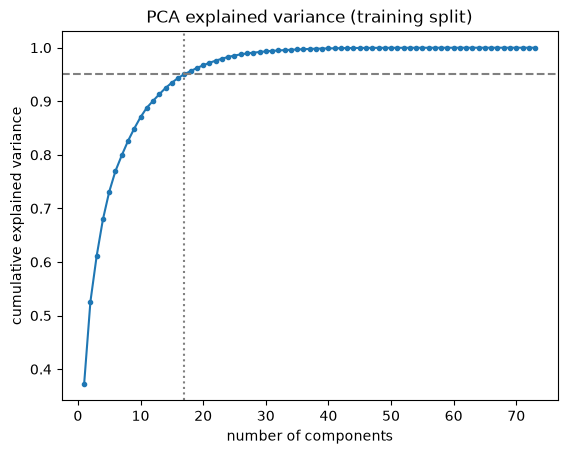

In [2]:
prep = build_preprocessor().fit(X_train)
Xt_train = prep.transform(X_train)
pca = PCA(random_state=RANDOM_STATE).fit(Xt_train)
cum_var = np.cumsum(pca.explained_variance_ratio_)
k95 = np.argmax(cum_var >= 0.95) + 1
print(f"components needed for 95% variance: {k95} out of {Xt_train.shape[1]}")

plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.95, color="gray", linestyle="--")
plt.axvline(k95, color="gray", linestyle=":")
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")
plt.title("PCA explained variance (training split)")
plt.savefig(FIGS / "lr_t2_pca_variance.png", dpi=150, bbox_inches="tight")
plt.show()

What do the first components actually measure? We look at the original features with the largest weights (loadings) in each of the first 3 components.

In [3]:
names = prep.get_feature_names_out()
loadings = pd.DataFrame(pca.components_[:3].T, index=names, columns=["PC1", "PC2", "PC3"])
for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index
    print(pc, "--->", ", ".join(f"{n} ({loadings.loc[n, pc]:+.2f})" for n in top))

PC1 ---> num__dwin (+0.24), num__swin (+0.23), log__sjit (+0.23), log__djit (+0.22), log__rate (-0.22)
PC2 ---> log__ct_state_ttl (+0.32), num__sttl (+0.30), log__dload (-0.28), log__tcprtt (+0.26), log__dloss (-0.25)
PC3 ---> log__ct_dst_src_ltm (+0.35), log__ct_srv_src (+0.34), log__ct_src_dport_ltm (+0.34), log__ct_srv_dst (+0.33), log__ct_dst_ltm (+0.27)


PC1 vs PC2 for a sample of training flows, colored by label. PCA never saw the labels, so any separation here comes from the structure of the data alone.

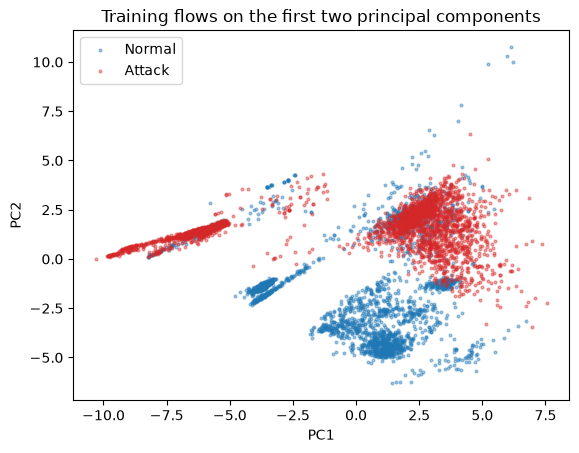

In [4]:
Z = pca.transform(Xt_train)[:, :2]
sample = np.random.default_rng(RANDOM_STATE).choice(len(Z), 5000, replace=False)
for label, name, color in [(0, "Normal", "tab:blue"), (1, "Attack", "tab:red")]:
    m = y_train.values[sample] == label
    plt.scatter(Z[sample][m, 0], Z[sample][m, 1], s=4, alpha=0.4, color=color, label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.title("Training flows on the first two principal components")
plt.savefig(FIGS / "lr_t2_pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

PCA only needs **17 of the 73 components** to keep 95% of the variance. The first component alone carries 37.3%, the first two 52.6%, and the curve is almost flat after about 30 components. So our 73 features really hold closer to 17 "directions" of information, which confirms the redundancy we saw in the EDA correlation matrix.

Looking at the top loadings, the first components have a clear meaning in network terms:
- **PC1** (37.3%): TCP window sizes (`swin`, `dwin`) and jitter (`sjit`, `djit`) on one side, `rate` on the other. It roughly separates real back-and-forth TCP conversations from fast, short one-shot flows.
- **PC2** (15.3%): the TTL features (`ct_state_ttl`, `sttl`) against how much the destination replies (`dload`, `dloss`). This is basically the "attack direction" from the EDA: attack TTL values and little reply.
- **PC3** (8.5%): all the `ct_` connection counts, i.e. how busy a host has been in its last 100 connections.

In the PC1 vs PC2 plot, normal and attack flows already split mostly along **PC2** (average PC2 of -1.63 for normal vs +1.51 for attacks), even though PCA never saw the labels. Attacks also form a long thin streak on the left, which looks like one heavily repeated attack pattern. But there is still an overlapping region in the middle, where the two classes are mixed.

**Why does this matter?**: PC2 shows that the TTL shortcut survives PCA ---> it will also be one of the strongest signals for this model. And since PCA keeps only 95% of the variance without looking at the label, the 5% it drops could carry signal for the hard cases in the overlapping region, so we expect this model to be somewhat limited (underfitting) rather than overfitting.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> PCA keeping 95% of the variance ---> logistic regression.

In [5]:
def build(C):
    return make_pipeline(build_preprocessor(),
                         PCA(n_components=0.95, random_state=RANDOM_STATE),
                         LogisticRegression(C=C, max_iter=2000))

**4. Regularization sweep**

We train one model for each of the 6 values of `C` (smaller `C` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [6]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "LR", "T2", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1 = 0.8942, fit time = 0.09s
C=0.01: val F1 = 0.8982, fit time = 0.07s
C=0.1: val F1 = 0.8996, fit time = 0.08s
C=1: val F1 = 0.8996, fit time = 0.06s
C=10: val F1 = 0.8998, fit time = 0.06s
C=100: val F1 = 0.8999, fit time = 0.05s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8420,0.9547,0.8948,0.1928,0.8460,0.9482,0.8942,0.1858,0.09,True,0.0006
1,0.010,0.8584,0.9375,0.8962,0.1665,0.8653,0.9338,0.8982,0.1564,0.07,True,-0.0020
2,0.100,0.8633,0.9339,0.8972,0.1592,0.8693,0.9322,0.8996,0.1509,0.08,True,-0.0024
3,1.000,0.8636,0.9330,0.8970,0.1587,0.8695,0.9318,0.8996,0.1505,0.06,True,-0.0026
4,10.000,0.8635,0.9330,0.8969,0.1588,0.8695,0.9322,0.8998,0.1505,0.06,True,-0.0028
5,100.000,0.8635,0.9330,0.8969,0.1588,0.8698,0.9322,0.8999,0.1502,0.05,True,-0.0030


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

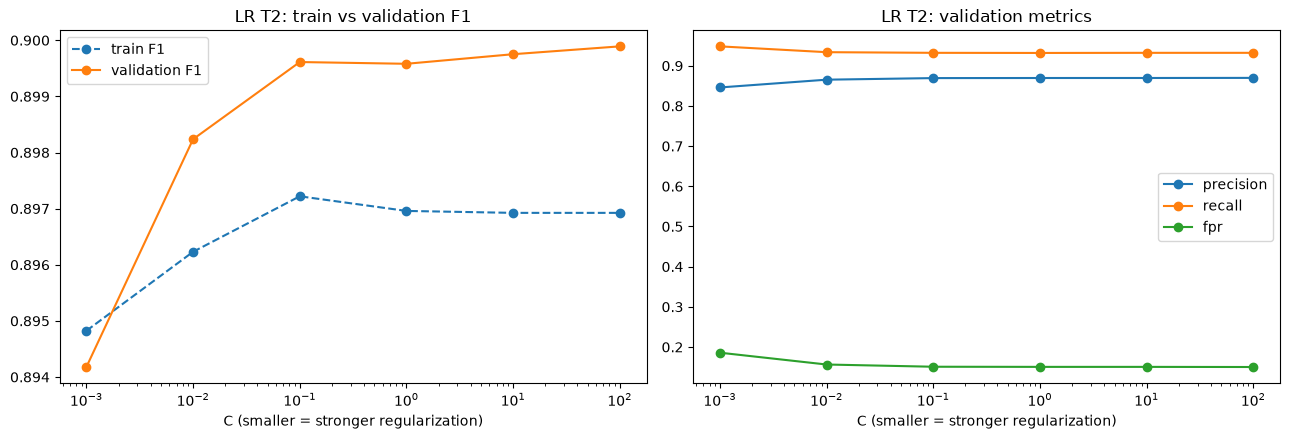

In [7]:
plot_sweep(results, "LR T2", FIGS / "curve_lr_t2_pca.png")

Validation F1 goes up from 0.8942 at `C` = 0.001 to 0.8996 at `C` = 0.1, and then stays flat (0.8996 to 0.8999) all the way to `C` = 100. The best value is technically `C` = 100, at the edge of the grid, but the curve is already flat and the differences after `C` = 0.1 are below 0.0003 ---> extending the grid would not help, so we keep it as is.

There is **no overfitting**: train and validation F1 are almost the same for every `C`, and validation is even slightly higher (gap between -0.003 and +0.001). Both are stuck around 0.90, which means the model is **underfitting** (high bias). This matches what we expected from the PCA check: a straight boundary on 17 components is simply not flexible enough, so weakening the regularization does not help.

What regularization does change is the trade-off between catching attacks and false alarms:
- Strong regularization (`C` = 0.001): recall 0.948, but FPR 0.186
- Weak regularization (`C` ≥ 0.1): recall 0.932, FPR drops to 0.150 and precision goes up from 0.846 to 0.870

**Why does this matter?**: Even the best FPR of 15% is far too high for a real network. At 1 million flows per day, it would mean about 150,000 false alarms daily ---> this model needs a more flexible transformation, or a higher decision threshold (see the planned extensions).

**6. The best setting**

We pick the `C` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [8]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best C = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best C = 100: val F1 = 0.8999, precision = 0.8698, recall = 0.9322, FPR = 0.1502
the best value is at the edge of the grid ---> consider extending it


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

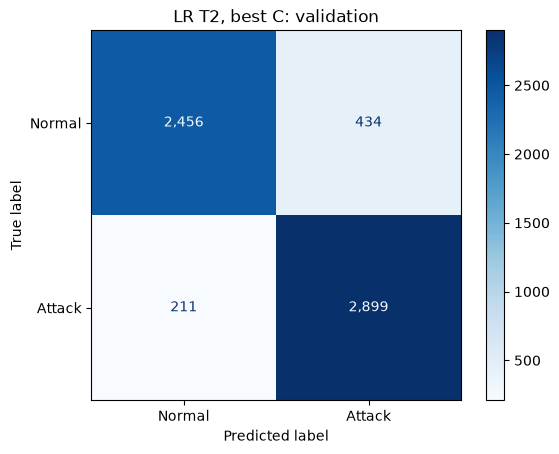

In [9]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("LR T2, best C: validation")
plt.savefig(FIGS / "confusion_lr_t2_pca.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [10]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,758,141,0.843
Backdoor,85,79,6,0.929
Analysis,89,85,4,0.955
Exploits,1105,1066,39,0.965
DoS,212,205,7,0.967
Generic,233,227,6,0.974
Reconnaissance,419,411,8,0.981
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


The best model (`C` = 100) makes 434 false alarms (15.0% of normal flows) and misses 211 attacks (6.8%), so most of its mistakes are false alarms.

**Fuzzers are by far the hardest attack type**: only 84.3% are caught, and the 141 missed Fuzzers make up two thirds of all missed attacks. This is what we expected from the EDA, where almost all of the 229 feature vectors with conflicting labels were Fuzzers vs Normal. Fuzzers send malformed data to a service, but at the flow level they look like an ordinary client talking to a server.

After Fuzzers, Exploits have the most misses in absolute terms (39), but they are still caught 96.5% of the time. Backdoor (92.9%) is the next lowest, but with only 85 rows that is just 6 misses. Shellcode and Worms are all caught, although Worms only has 7 rows in validation, so we cannot say much about it.

**Why does this matter?**: The weakness is concentrated in one attack type ---> when we compare the transformations, we should check whether the more flexible ones (T3, MLP) catch more Fuzzers, not only whether the overall F1 goes up.

**7. Save the results**

We save the 6 rows to `results/lr_t2_pca.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [11]:
results.to_csv(RESULTS / "lr_t2_pca.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "lr_t2_pca.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/lr_t2_pca.csv
